## 1. Import Library yang Dibutuhkan


In [1]:
# Install library jika belum terpasang di Colab:
!pip install scikit-image opencv-python matplotlib seaborn scikit-learn joblib

import os
import time
import json
import shutil
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import drive

# Library Machine Learning & Evaluasi
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Library Ekstraksi Fitur Tekstur GLCM
from skimage.feature import graycomatrix, graycoprops

# Library Deep Learning (TensorFlow / Keras)
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

# Random seed agar hasil konsisten
np.random.seed(42)
tf.random.set_seed(42)

print("Versi TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print("Status Akselerasi:", "GPU Aktif" if gpus else "CPU (Standard)")


Versi TensorFlow: 2.21.0
Status Akselerasi: GPU Aktif


## 2. Pengaturan Path Dataset MLA


In [2]:
# Pengaturan direktori dataset MLA
drive.mount('/content/drive')
DATASET_DIR = "/content/drive/MyDrive/Dataset_Citra_Tulisan_Tangan"

if not os.path.isdir(DATASET_DIR):
    raise FileNotFoundError(f"Dataset tidak ditemukan: {DATASET_DIR}")

print("Path dataset aktif:", os.path.abspath(DATASET_DIR))

Mounted at /content/drive
Path dataset aktif: /content/drive/MyDrive/Dataset_Citra_Tulisan_Tangan


## 3. Membaca Citra dan Label Kelas
Karena dataset sudah distandarisasi (seluruh lembar asli telah dipisahkan ke dalam subfolder `Original/`), pembacaan file menjadi sangat ringkas: cukup membaca file citra yang berada langsung di dalam folder kelas masing-masing.


In [3]:
image_paths = []
labels = []

kelas_list = sorted([d for d in os.listdir(DATASET_DIR) if os.path.isdir(os.path.join(DATASET_DIR, d))])
print(f"Total kelas mahasiswa terdaftar: {len(kelas_list)}")

for kelas in kelas_list:
    kelas_dir = os.path.join(DATASET_DIR, kelas)
    for f in sorted(os.listdir(kelas_dir)):
        f_path = os.path.join(kelas_dir, f)
        # Ambil file gambar di root folder kelas (mengabaikan subfolder Original dan non-citra/PDF)
        if os.path.isfile(f_path) and f.lower().endswith(('.jpg', '.jpeg', '.png')):
            image_paths.append(f_path)
            labels.append(kelas)

print(f"Total citra tulisan tangan yang berhasil dimuat: {len(image_paths)}")

Total kelas mahasiswa terdaftar: 51
Total citra tulisan tangan yang berhasil dimuat: 2782


### Visualisasi Sampel Citra Tulisan Tangan


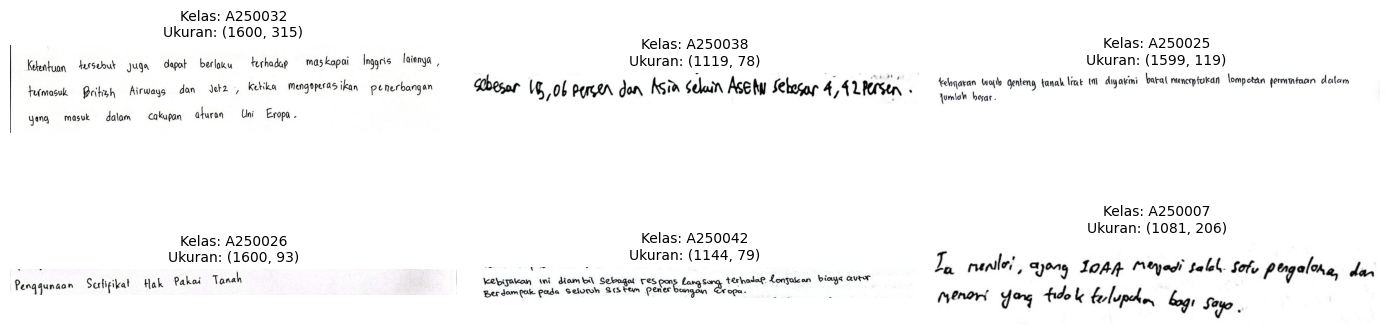

In [4]:
# Menampilkan 6 sampel citra secara acak
fig, axes = plt.subplots(2, 3, figsize=(14, 5))
sample_indices = np.random.choice(len(image_paths), 6, replace=False)

for idx, ax in zip(sample_indices, axes.flatten()):
    img = Image.open(image_paths[idx])
    ax.imshow(img, cmap='gray' if img.mode == 'L' else None)
    ax.set_title(f"Kelas: {labels[idx]}\nUkuran: {img.size}", fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.show()

## 4. Ekstraksi Fitur Tekstur GLCM (24 Fitur dengan Letterboxing)
Mengekstraksi **24 fitur tekstur GLCM** (6 properti Haralick: *Contrast, Dissimilarity, Homogeneity, Energy, Correlation, ASM* $\times$ 4 sudut orientasi: $0^\circ, 45^\circ, 90^\circ, 135^\circ$) dengan jarak $d=1$ piksel pada citra grayscale berukuran $128 \times 128$ yang diproses menggunakan teknik **letterboxing** untuk mempertahankan rasio aspek alami dan arah kemiringan tulisan (*slant angle*), serta **mencatat total waktu ekstraksi**.

In [5]:
IMG_SIZE = (128, 128)

def resize_with_letterbox(img, target_size=IMG_SIZE, bg_color=(230, 230, 230)):
    """
    Mengubah ukuran citra dengan mempertahankan aspek rasio (letterbox),
    dan menempatkannya di tengah kanvas berukuran target_size dengan warna latar netral.
    """
    img_copy = img.copy()
    img_copy.thumbnail(target_size, Image.Resampling.LANCZOS)
    if img_copy.mode == 'L':
        fill_val = bg_color if isinstance(bg_color, int) else bg_color[0]
        canvas = Image.new('L', target_size, fill_val)
    else:
        fill_val = bg_color if isinstance(bg_color, tuple) else (bg_color, bg_color, bg_color)
        canvas = Image.new('RGB', target_size, fill_val)
        if img_copy.mode != 'RGB':
            img_copy = img_copy.convert('RGB')
    offset = ((target_size[0] - img_copy.size[0]) // 2, (target_size[1] - img_copy.size[1]) // 2)
    canvas.paste(img_copy, offset)
    return canvas

def extract_glcm(path_citra):
    raw_img = Image.open(path_citra)
    # Preprocessing letterbox & konversi ke Grayscale
    lb_img = resize_with_letterbox(raw_img, target_size=IMG_SIZE, bg_color=230)
    gray_img = lb_img.convert('L')
    img_arr = np.array(gray_img, dtype=np.uint8)

    # Hitung matriks GLCM
    glcm = graycomatrix(
        img_arr,
        distances=[1],
        angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
        levels=256,
        symmetric=True,
        normed=True
    )

    # Ekstraksi 24 fitur (6 properti Haralick x 4 orientasi sudut)
    props = ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation', 'ASM']
    features = []
    for p in props:
        val_matrix = graycoprops(glcm, p)  # shape: (1, 4)
        for angle_idx in range(val_matrix.shape[1]):
            features.append(float(val_matrix[0, angle_idx]))
    return features

print("Memulai ekstraksi fitur tekstur GLCM (24 fitur per citra dengan letterbox)...")
t_awal_glcm = time.time()

X_glcm = np.array([extract_glcm(p) for p in image_paths])
waktu_ekstraksi_glcm = time.time() - t_awal_glcm

print("\n" + "="*50)
print(f"WAKTU EKSTRAKSI FITUR GLCM : {waktu_ekstraksi_glcm:.2f} detik")
print(f"Rata-rata per citra        : {(waktu_ekstraksi_glcm / len(image_paths)):.4f} detik")
print(f"Dimensi Array Fitur GLCM   : {X_glcm.shape} (24 fitur)")
print("="*50)

Memulai ekstraksi fitur tekstur GLCM...

WAKTU EKSTRAKSI FITUR GLCM : 1122.21 detik
Rata-rata per citra        : 0.4034 detik
Dimensi Array Fitur GLCM   : (2782, 6)


## 5. Persiapan Data Deep Learning & Setup 5-Fold Cross Validation
Menyiapkan array citra RGB ternormalisasi `[0, 1]` dengan teknik **letterboxing** (agar proporsi teks terjaga) dan pembagian 5-Fold Cross Validation untuk 5 skenario eksperimen.

In [6]:
# Label encoding kelas mahasiswa ke angka 0 s.d. 50
le = LabelEncoder()
y_encoded = le.fit_transform(labels)
num_classes = len(le.classes_)

# Preprocessing citra RGB untuk Deep Learning dengan Letterboxing
print("Memuat citra untuk Deep Learning (menggunakan letterboxing)...")
X_images = np.array([
    np.array(resize_with_letterbox(Image.open(p), target_size=IMG_SIZE, bg_color=(230, 230, 230)).convert('RGB'), dtype=np.float32) / 255.0
    for p in image_paths
])
print("Dimensi tensor citra DL:", X_images.shape)

# Setup 5-Fold Cross Validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
k_folds = list(skf.split(X_glcm, y_encoded))
print(f"Siap menjalankan 5 Skenario Eksperimen (5-Fold CV).")

Memuat citra untuk Deep Learning...
Dimensi tensor citra DL: (2782, 128, 128, 3)
Siap menjalankan 5 Skenario Eksperimen (5-Fold CV).


## 6. Eksperimen Klasifikasi Machine Learning (+ GLCM)
### 6.1. Algoritma 1: Support Vector Machine (SVM) + GLCM


In [7]:
hasil_svm = []
print("=== EKSPERIMEN ALGORITMA 1: SVM + GLCM ===")

for fold_no, (train_idx, test_idx) in enumerate(k_folds, start=1):
    X_train, X_test = X_glcm[train_idx], X_glcm[test_idx]
    y_train, y_test = y_encoded[train_idx], y_encoded[test_idx]

    # Standarisasi fitur
    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)
    X_test_s = scaler.transform(X_test)

    # Model SVM (Kernel RBF)
    model = SVC(kernel='rbf', C=10.0, random_state=42)

    t0 = time.time()
    model.fit(X_train_s, y_train)
    durasi = time.time() - t0

    y_pred = model.predict(X_test_s)

    hasil_svm.append({
        'Eksperimen ke': fold_no,
        'Precision': round(precision_score(y_test, y_pred, average='macro', zero_division=0), 4),
        'Recall': round(recall_score(y_test, y_pred, average='macro', zero_division=0), 4),
        'Akurasi': round(accuracy_score(y_test, y_pred), 4),
        'F1-Score': round(f1_score(y_test, y_pred, average='macro', zero_division=0), 4),
        'Waktu Pelatihan': round(durasi, 4)
    })
    print(f"Eksperimen {fold_no} -> Akurasi: {hasil_svm[-1]['Akurasi']} | Waktu: {durasi:.4f}s")

df_svm = pd.DataFrame(hasil_svm)
rata_svm = {
    'Eksperimen ke': 'Rata-Rata',
    'Precision': round(df_svm['Precision'].mean(), 4),
    'Recall': round(df_svm['Recall'].mean(), 4),
    'Akurasi': round(df_svm['Akurasi'].mean(), 4),
    'F1-Score': round(df_svm['F1-Score'].mean(), 4),
    'Waktu Pelatihan': round(df_svm['Waktu Pelatihan'].mean(), 4)
}
df_svm = pd.concat([df_svm, pd.DataFrame([rata_svm])], ignore_index=True)
display(df_svm)


=== EKSPERIMEN ALGORITMA 1: SVM + GLCM ===
Eksperimen 1 -> Akurasi: 0.5781 | Waktu: 0.1374s
Eksperimen 2 -> Akurasi: 0.5889 | Waktu: 0.1347s
Eksperimen 3 -> Akurasi: 0.5719 | Waktu: 0.1316s
Eksperimen 4 -> Akurasi: 0.5791 | Waktu: 0.1385s
Eksperimen 5 -> Akurasi: 0.5665 | Waktu: 0.1362s


,Eksperimen ke,Precision,Recall,Akurasi,F1-Score,Waktu Pelatihan
0,1,0.5824,0.5743,0.5781,0.5553,0.1374
1,2,0.5776,0.5843,0.5889,0.5692,0.1347
2,3,0.5813,0.5704,0.5719,0.5560,0.1316
3,4,0.5806,0.5825,0.5791,0.5670,0.1385
4,5,0.5840,0.5726,0.5665,0.5572,0.1362
5,Rata-Rata,0.5812,0.5768,0.5769,0.5609,0.1357


### 6.2. Algoritma 2: Random Forest + GLCM


In [8]:
hasil_rf = []
print("=== EKSPERIMEN ALGORITMA 2: RANDOM FOREST + GLCM ===")

for fold_no, (train_idx, test_idx) in enumerate(k_folds, start=1):
    X_train, X_test = X_glcm[train_idx], X_glcm[test_idx]
    y_train, y_test = y_encoded[train_idx], y_encoded[test_idx]

    model = RandomForestClassifier(n_estimators=100, random_state=42)

    t0 = time.time()
    model.fit(X_train, y_train)
    durasi = time.time() - t0

    y_pred = model.predict(X_test)

    hasil_rf.append({
        'Eksperimen ke': fold_no,
        'Precision': round(precision_score(y_test, y_pred, average='macro', zero_division=0), 4),
        'Recall': round(recall_score(y_test, y_pred, average='macro', zero_division=0), 4),
        'Akurasi': round(accuracy_score(y_test, y_pred), 4),
        'F1-Score': round(f1_score(y_test, y_pred, average='macro', zero_division=0), 4),
        'Waktu Pelatihan': round(durasi, 4)
    })
    print(f"Eksperimen {fold_no} -> Akurasi: {hasil_rf[-1]['Akurasi']} | Waktu: {durasi:.4f}s")

df_rf = pd.DataFrame(hasil_rf)
rata_rf = {
    'Eksperimen ke': 'Rata-Rata',
    'Precision': round(df_rf['Precision'].mean(), 4),
    'Recall': round(df_rf['Recall'].mean(), 4),
    'Akurasi': round(df_rf['Akurasi'].mean(), 4),
    'F1-Score': round(df_rf['F1-Score'].mean(), 4),
    'Waktu Pelatihan': round(df_rf['Waktu Pelatihan'].mean(), 4)
}
df_rf = pd.concat([df_rf, pd.DataFrame([rata_rf])], ignore_index=True)
display(df_rf)


=== EKSPERIMEN ALGORITMA 2: RANDOM FOREST + GLCM ===
Eksperimen 1 -> Akurasi: 0.5422 | Waktu: 1.0370s
Eksperimen 2 -> Akurasi: 0.5171 | Waktu: 1.0334s
Eksperimen 3 -> Akurasi: 0.4928 | Waktu: 1.0277s
Eksperimen 4 -> Akurasi: 0.5432 | Waktu: 1.0721s
Eksperimen 5 -> Akurasi: 0.5288 | Waktu: 1.0541s


,Eksperimen ke,Precision,Recall,Akurasi,F1-Score,Waktu Pelatihan
0,1,0.5289,0.5374,0.5422,0.5225,1.0370
1,2,0.5290,0.5151,0.5171,0.5068,1.0334
2,3,0.4837,0.4895,0.4928,0.4772,1.0277
3,4,0.5304,0.5407,0.5432,0.5274,1.0721
4,5,0.5298,0.5334,0.5288,0.5222,1.0541
5,Rata-Rata,0.5204,0.5232,0.5248,0.5112,1.0449


## 7. Eksperimen Klasifikasi Deep Learning: Transfer Learning & Fine-Tuning (MobileNetV2)
Menggunakan arsitektur MobileNetV2 pre-trained ImageNet yang disesuaikan dengan layer **Data Augmentation** (rotasi, zoom, kontras) serta **Fine-Tuning** pada 30 layer konvolusi teratas agar mampu mempelajari representasi fitur mikroskopis goresan pena tulisan tangan.

In [9]:
def build_mobilenet(input_shape=(128, 128, 3), n_classes=num_classes):
    base = MobileNetV2(weights='imagenet', include_top=False, input_shape=input_shape)
    
    # Fine-tuning: buka unfreeze pada 30 layer teratas agar belajar representasi goresan tulisan tangan
    base.trainable = True
    for layer in base.layers[:-30]:
        layer.trainable = False

    data_augmentation = tf.keras.Sequential([
        layers.RandomRotation(0.04),
        layers.RandomZoom(0.06),
        layers.RandomContrast(0.12),
    ])

    inputs = tf.keras.Input(shape=input_shape)
    x = data_augmentation(inputs)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation='relu')(x)
    outputs = layers.Dense(n_classes, activation='softmax')(x)

    model = tf.keras.Model(inputs=inputs, outputs=outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=2e-4),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

hasil_mb = []
print("=== EKSPERIMEN DEEP LEARNING 2: MOBILENETV2 (5 FOLDS) ===")

for fold_no, (train_idx, test_idx) in enumerate(k_folds, start=1):
    X_train, X_test = X_images[train_idx], X_images[test_idx]
    y_train, y_test = y_encoded[train_idx], y_encoded[test_idx]

    model = build_mobilenet()
    t0 = time.time()
    model.fit(X_train, y_train, epochs=12, batch_size=32, verbose=0)
    durasi = time.time() - t0

    y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)

    hasil_mb.append({
        'Eksperimen ke': fold_no,
        'Precision': round(precision_score(y_test, y_pred, average='macro', zero_division=0), 4),
        'Recall': round(recall_score(y_test, y_pred, average='macro', zero_division=0), 4),
        'Akurasi': round(accuracy_score(y_test, y_pred), 4),
        'F1-Score': round(f1_score(y_test, y_pred, average='macro', zero_division=0), 4),
        'Waktu Pelatihan': round(durasi, 4)
    })
    print(f"Eksperimen {fold_no} -> Akurasi: {hasil_mb[-1]['Akurasi']} | Waktu: {durasi:.2f}s")

df_mb = pd.DataFrame(hasil_mb)
rata_mb = {
    'Eksperimen ke': 'Rata-Rata',
    'Precision': round(df_mb['Precision'].mean(), 4),
    'Recall': round(df_mb['Recall'].mean(), 4),
    'Akurasi': round(df_mb['Akurasi'].mean(), 4),
    'F1-Score': round(df_mb['F1-Score'].mean(), 4),
    'Waktu Pelatihan': round(df_mb['Waktu Pelatihan'].mean(), 4)
}
df_mb = pd.concat([df_mb, pd.DataFrame([rata_mb])], ignore_index=True)
display(df_mb)

=== EKSPERIMEN DEEP LEARNING 2: MOBILENETV2 (5 FOLDS) ===
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Eksperimen 1 -> Akurasi: 0.7756 | Waktu: 46.45s
Eksperimen 2 -> Akurasi: 0.772 | Waktu: 20.51s
Eksperimen 3 -> Akurasi: 0.75 | Waktu: 32.15s
Eksperimen 4 -> Akurasi: 0.7464 | Waktu: 19.91s
Eksperimen 5 -> Akurasi: 0.7644 | Waktu: 19.81s


,Eksperimen ke,Precision,Recall,Akurasi,F1-Score,Waktu Pelatihan
0,1,0.8092,0.7726,0.7756,0.7665,46.4463
1,2,0.8006,0.7655,0.7720,0.7644,20.5125
2,3,0.7969,0.7433,0.7500,0.7412,32.1507
3,4,0.7814,0.7484,0.7464,0.7414,19.9097
4,5,0.7960,0.7676,0.7644,0.7617,19.8059
5,Rata-Rata,0.7968,0.7595,0.7617,0.7550,27.7650


## 8. Rekapitulasi Hasil Eksperimen Sesuai Format Tugas (Halaman 3)


In [10]:
df_rekapitulasi = pd.DataFrame([
    {
        'Nama Algoritma': 'Algoritma 1 (SVM + GLCM)',
        'Rata-Rata Precision': rata_svm['Precision'],
        'Rata-Rata Recall': rata_svm['Recall'],
        'Rata-Rata Akurasi': rata_svm['Akurasi'],
        'Rata-Rata F1-Score': rata_svm['F1-Score'],
        'Rata-Rata Waktu Pelatihan': rata_svm['Waktu Pelatihan']
    },
    {
        'Nama Algoritma': 'Algoritma 2 (Random Forest + GLCM)',
        'Rata-Rata Precision': rata_rf['Precision'],
        'Rata-Rata Recall': rata_rf['Recall'],
        'Rata-Rata Akurasi': rata_rf['Akurasi'],
        'Rata-Rata F1-Score': rata_rf['F1-Score'],
        'Rata-Rata Waktu Pelatihan': rata_rf['Waktu Pelatihan']
    },
    {
        'Nama Algoritma': 'Arsitektur DL (MobileNetV2)',
        'Rata-Rata Precision': rata_mb['Precision'],
        'Rata-Rata Recall': rata_mb['Recall'],
        'Rata-Rata Akurasi': rata_mb['Akurasi'],
        'Rata-Rata F1-Score': rata_mb['F1-Score'],
        'Rata-Rata Waktu Pelatihan': rata_mb['Waktu Pelatihan']
    }
])

print("="*85)
print("                    REKAP HASIL EKSPERIMEN (FORMAT LAPORAN)")
print("="*85)
display(df_rekapitulasi)
print("="*85)
print(f"Total Waktu Ekstraksi Fitur GLCM: {waktu_ekstraksi_glcm:.2f} detik")
print("="*85)


                    REKAP HASIL EKSPERIMEN (FORMAT LAPORAN)


,Nama Algoritma,Rata-Rata Precision,Rata-Rata Recall,Rata-Rata Akurasi,Rata-Rata F1-Score,Rata-Rata Waktu Pelatihan
0,Algoritma 1 (SVM + GLCM),0.5812,0.5768,0.5769,0.5609,0.1357
1,Algoritma 2 (Random Forest + GLCM),0.5204,0.5232,0.5248,0.5112,1.0449
2,Arsitektur DL (MobileNetV2),0.7968,0.7595,0.7617,0.7550,27.7650


Total Waktu Ekstraksi Fitur GLCM: 1122.21 detik


## 9. Visualisasi Grafik Perbandingan Model


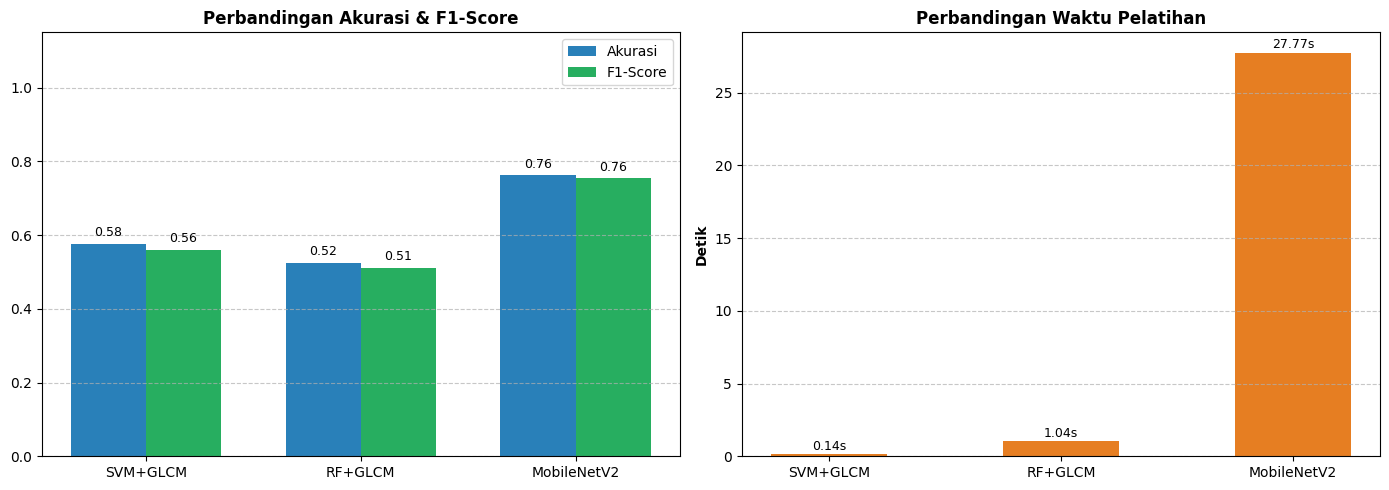

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
models_name = ['SVM+GLCM', 'RF+GLCM', 'MobileNetV2']

# Grafik 1: Akurasi & F1-Score
acc_vals = [rata_svm['Akurasi'], rata_rf['Akurasi'], rata_mb['Akurasi']]
f1_vals = [rata_svm['F1-Score'], rata_rf['F1-Score'], rata_mb['F1-Score']]
x = np.arange(len(models_name))
w = 0.35

ax1.bar(x - w/2, acc_vals, w, label='Akurasi', color='#2980b9')
ax1.bar(x + w/2, f1_vals, w, label='F1-Score', color='#27ae60')
ax1.set_xticks(x)
ax1.set_xticklabels(models_name)
ax1.set_ylim(0, 1.15)
ax1.set_title('Perbandingan Akurasi & F1-Score', fontweight='bold')
ax1.legend()
ax1.grid(axis='y', linestyle='--', alpha=0.7)
for i in range(len(models_name)):
    ax1.text(x[i] - w/2, acc_vals[i] + 0.02, f"{acc_vals[i]:.2f}", ha='center', fontsize=9)
    ax1.text(x[i] + w/2, f1_vals[i] + 0.02, f"{f1_vals[i]:.2f}", ha='center', fontsize=9)

# Grafik 2: Waktu Pelatihan
waktu_vals = [rata_svm['Waktu Pelatihan'], rata_rf['Waktu Pelatihan'], rata_mb['Waktu Pelatihan']]
ax2.bar(models_name, waktu_vals, color='#e67e22', width=0.5)
ax2.set_ylabel('Detik', fontweight='bold')
ax2.set_title('Perbandingan Waktu Pelatihan', fontweight='bold')
ax2.grid(axis='y', linestyle='--', alpha=0.7)
for i, v in enumerate(waktu_vals):
    ax2.text(i, v + (max(waktu_vals)*0.01 if max(waktu_vals) > 0 else 0.01), f"{v:.2f}s", ha='center', fontsize=9)

plt.tight_layout()
plt.show()


## 10. Pelatihan Model Final (100% Data) & Export Model untuk Backend FastAPI
Pada tahap ini:
1. **Pemetaan Label (`classes.json`) & Metadata**: Disimpan dengan konfigurasi 24 fitur GLCM dan letterbox agar backend FastAPI mengetahui dimensi input dan preprocessing yang tepat.
2. **MobileNetV2**: Dilatih ulang menggunakan seluruh dataset (100% data) dengan data augmentation dan fine-tuning selama 15 epochs untuk mendapatkan bobot optimal, lalu diekspor dalam format `.keras` dan `.h5`.
3. **Model Machine Learning (SVM & Random Forest) + GLCM Scaler**: Dilatih ulang pada seluruh 24 fitur GLCM dan diekspor menggunakan `joblib`.
4. **Verifikasi Inferensi**: Uji coba langsung memuat model yang diekspor dan melakukan prediksi pada 1 citra sampel untuk memastikan format file valid.

In [12]:
# Pengaturan direktori penyimpanan model untuk FastAPI
EXPORT_DIR = "model_export"
os.makedirs(EXPORT_DIR, exist_ok=True)
print(f"Direktori ekspor aktif: {os.path.abspath(EXPORT_DIR)}")

# 1. Export Pemetaan Label (classes.json)
class_mapping = {int(idx): str(label) for idx, label in enumerate(le.classes_)}
with open(os.path.join(EXPORT_DIR, "classes.json"), "w", encoding="utf-8") as f:
    json.dump(class_mapping, f, indent=4)

# Export LabelEncoder objek
joblib.dump(le, os.path.join(EXPORT_DIR, "label_encoder.joblib"))

# 2. Export Metadata Preprocessing & Konfigurasi Citra
metadata = {
    "num_classes": int(num_classes),
    "classes": list(map(str, le.classes_)),
    "image_size": list(IMG_SIZE),
    "channels": 3,
    "normalization": "div_255",
    "preprocessing": "letterbox_128x128",
    "num_glcm_features": 24,
    "glcm_config": {
        "properties": ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation', 'ASM'],
        "distances": [1],
        "angles": [0, 45, 90, 135],
        "total_features": 24
    }
}
with open(os.path.join(EXPORT_DIR, "metadata.json"), "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4)

print("[OK] classes.json, label_encoder.joblib, dan metadata.json berhasil diekspor.")

Direktori ekspor aktif: /content/model_export
[OK] classes.json, label_encoder.joblib, dan metadata.json berhasil diekspor.


In [13]:
print("="*65)
print("1. MELATIH ULANG MOBILENETV2 PADA 100% DATASET (FINE-TUNED + LETTERBOX)...")
print("="*65)

# Inisialisasi arsitektur MobileNetV2 baru
final_mobilenet = build_mobilenet(input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3), n_classes=num_classes)

# Latih pada seluruh data citra (15 epochs dengan data augmentation)
t_start_train_mb = time.time()
final_mobilenet.fit(X_images, y_encoded, epochs=15, batch_size=32, verbose=1)
waktu_train_mb = time.time() - t_start_train_mb
print(f"Pelatihan MobileNetV2 selesai dalam {waktu_train_mb:.2f} detik.")

# Simpan dalam format native modern Keras (.keras) dan legacy HDF5 (.h5)
keras_path = os.path.join(EXPORT_DIR, "mobilenetv2_final.keras")
h5_path = os.path.join(EXPORT_DIR, "mobilenetv2_final.h5")

final_mobilenet.save(keras_path)
print(f"[EXPORTED] Format modern Keras : {keras_path}")

try:
    final_mobilenet.save(h5_path)
    print(f"[EXPORTED] Format HDF5 (.h5)  : {h5_path}")
except Exception as e:
    print(f"[Catatan] Ekspor format .h5 dilewati: {e}")

1. MELATIH ULANG MOBILENETV2 PADA 100% DATASET...
Epoch 1/10
87/87 ━━━━━━━━━━━━━━━━━━━━ 26s 205ms/step - accuracy: 0.2426 - loss: 3.0934
Epoch 2/10
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.5478 - loss: 1.6667
Epoch 3/10
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.6643 - loss: 1.1563
Epoch 4/10
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.7387 - loss: 0.9025
Epoch 5/10
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.7883 - loss: 0.7193
Epoch 6/10
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8120 - loss: 0.6276
Epoch 7/10
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.8386 - loss: 0.5302
Epoch 8/10
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.8638 - loss: 0.4682
Epoch 9/10
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.8602 - loss: 0.4336
Epoch 10/10
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.8821 - loss: 0.3875
Pelatihan MobileNetV2 selesai dalam 38.33 detik.


[EXPORTED] Format modern Keras : model_export/mobilenetv2_final.keras
[EXPORTED] Format HDF5 (.h5)  : model_export/mobilenetv2_final.h5


In [14]:
print("="*65)
print("2. MELATIH ULANG SVM & RANDOM FOREST PADA 100% DATASET (24 FITUR GLCM)...")
print("="*65)

# A. Fit StandardScaler pada seluruh data GLCM (24 fitur)
final_scaler = StandardScaler()
X_glcm_scaled = final_scaler.fit_transform(X_glcm)
scaler_path = os.path.join(EXPORT_DIR, "glcm_scaler.joblib")
joblib.dump(final_scaler, scaler_path)
print(f"[EXPORTED] Scaler GLCM (24 features): {scaler_path}")

# B. Latih SVM pada seluruh data GLCM (24 fitur)
# probability=True digunakan agar model SVM dapat menghasilkan confidence score (predict_proba) di FastAPI
print("Melatih Final SVM...")
t_start_svm = time.time()
final_svm = SVC(kernel='rbf', C=10.0, probability=True, random_state=42)
final_svm.fit(X_glcm_scaled, y_encoded)
waktu_train_svm = time.time() - t_start_svm
svm_path = os.path.join(EXPORT_DIR, "svm_glcm_final.joblib")
joblib.dump(final_svm, svm_path)
print(f"[EXPORTED] Final SVM Model    : {svm_path} (Pelatihan: {waktu_train_svm:.2f}s)")

# C. Latih Random Forest pada seluruh data GLCM (24 fitur)
print("Melatih Final Random Forest...")
t_start_rf = time.time()
final_rf = RandomForestClassifier(n_estimators=100, random_state=42)
final_rf.fit(X_glcm, y_encoded)
waktu_train_rf = time.time() - t_start_rf
rf_path = os.path.join(EXPORT_DIR, "rf_glcm_final.joblib")
joblib.dump(final_rf, rf_path)
print(f"[EXPORTED] Final Random Forest: {rf_path} (Pelatihan: {waktu_train_rf:.2f}s)")

2. MELATIH ULANG SVM & RANDOM FOREST PADA 100% DATASET...
[EXPORTED] Scaler GLCM        : model_export/glcm_scaler.joblib
Melatih Final SVM...
[EXPORTED] Final SVM Model    : model_export/svm_glcm_final.joblib (Pelatihan: 1.22s)
Melatih Final Random Forest...
[EXPORTED] Final Random Forest: model_export/rf_glcm_final.joblib (Pelatihan: 1.34s)


### 10.1. Verifikasi Uji Inferensi (Sanity Check)
Memuat file-file model dan metadata yang telah diekspor untuk mensimulasikan alur inferensi prediksi yang akan dijalankan oleh backend FastAPI.


In [15]:
print("=== VERIFIKASI HASIL EXPORT UNTUK INFERENSI FASTAPI ===")

# 1. Muat kembali pemetaan kelas dari classes.json
with open(os.path.join(EXPORT_DIR, "classes.json"), "r", encoding="utf-8") as f:
    loaded_classes = json.load(f)

# 2. Muat model MobileNetV2
loaded_mb = tf.keras.models.load_model(os.path.join(EXPORT_DIR, "mobilenetv2_final.keras"))

# 3. Muat model ML & Scaler
loaded_scaler = joblib.load(os.path.join(EXPORT_DIR, "glcm_scaler.joblib"))
loaded_svm = joblib.load(os.path.join(EXPORT_DIR, "svm_glcm_final.joblib"))
loaded_rf = joblib.load(os.path.join(EXPORT_DIR, "rf_glcm_final.joblib"))

# 4. Ambil 1 citra uji untuk simulasi request inferensi
sample_idx = 0
sample_path = image_paths[sample_idx]
sample_true_label = labels[sample_idx]

print(f"Citra Sampel Uji     : {os.path.basename(sample_path)}")
print(f"Label Sebenarnya     : {sample_true_label}")
print("-" * 50)

# Simulasi Inferensi A: MobileNetV2 dengan Letterboxing
img_test = resize_with_letterbox(Image.open(sample_path), target_size=IMG_SIZE, bg_color=(230, 230, 230)).convert('RGB')
img_tensor = np.expand_dims(np.array(img_test, dtype=np.float32) / 255.0, axis=0)
mb_probs = loaded_mb.predict(img_tensor, verbose=0)[0]
mb_pred_idx = int(np.argmax(mb_probs))
mb_pred_label = loaded_classes[str(mb_pred_idx)]
mb_conf = float(mb_probs[mb_pred_idx])
print(f"[MobileNetV2] Prediksi : {mb_pred_label} (Confidence: {mb_conf*100:.2f}%)")

# Simulasi Inferensi B: Ekstraksi GLCM 24 Fitur + SVM & RF
sample_glcm = np.array([extract_glcm(sample_path)])
sample_glcm_scaled = loaded_scaler.transform(sample_glcm)

# SVM
svm_probs = loaded_svm.predict_proba(sample_glcm_scaled)[0]
svm_pred_idx = int(np.argmax(svm_probs))
svm_pred_label = loaded_classes[str(svm_pred_idx)]
svm_conf = float(svm_probs[svm_pred_idx])
print(f"[SVM + GLCM]  Prediksi : {svm_pred_label} (Confidence: {svm_conf*100:.2f}%)")

# RF
rf_probs = loaded_rf.predict_proba(sample_glcm)[0]
rf_pred_idx = int(np.argmax(rf_probs))
rf_pred_label = loaded_classes[str(rf_pred_idx)]
rf_conf = float(rf_probs[rf_pred_idx])
print(f"[RF + GLCM]   Prediksi : {rf_pred_label} (Confidence: {rf_conf*100:.2f}%)")

print("-" * 50)
print("[STATUS] Seluruh model dan metadata berhasil dimuat serta siap diintegrasikan ke FastAPI!")

=== VERIFIKASI HASIL EXPORT UNTUK INFERENSI FASTAPI ===
Citra Sampel Uji     : 535220199_1.jpg
Label Sebenarnya     : A220199
--------------------------------------------------
[MobileNetV2] Prediksi : A220199 (Confidence: 98.41%)
[SVM + GLCM]  Prediksi : A250038 (Confidence: 38.16%)
[RF + GLCM]   Prediksi : A220199 (Confidence: 80.00%)
--------------------------------------------------
[STATUS] Seluruh model dan metadata berhasil dimuat serta siap diintegrasikan ke FastAPI!


In [16]:
# Membuat arsip .zip dari direktori model_export
zip_output = shutil.make_archive("model_export", 'zip', EXPORT_DIR)
print(f"Direktori ekspor telah dikompres menjadi: {zip_output}")
print("Anda dapat mengunduh file 'model_export.zip' ini untuk dipindahkan ke folder backend FastAPI Anda.")

from google.colab import files
files.download("model_export.zip")


Direktori ekspor telah dikompres menjadi: /content/model_export.zip
Anda dapat mengunduh file 'model_export.zip' ini untuk dipindahkan ke folder backend FastAPI Anda.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>